# Task 6 — Final Capstone: Predicting Breast Cancer Malignancy from Cell Measurements
**YuvaIntern · Data Analyst Internship** · **Intern:** Rashad kazi

## 1. Problem definition
**Background.** A fine needle aspirate (FNA) is a quick, low-cost biopsy: a thin needle draws cells from a breast lump, the sample is photographed under a microscope, and software measures the cell nuclei. A doctor then decides whether the lump is **malignant** (cancer) or **benign**.

**Problem statement.** Build and evaluate a machine-learning model that classifies a lump as malignant or benign from the 30 nucleus measurements, to act as a *second-opinion screening aid* for clinicians.

**Objectives**
1. Explore which cell characteristics differ most between malignant and benign samples.
2. Train and compare several classification models with a fair, leak-free process.
3. Select a model and decision threshold that put patient safety first.
4. Analyse errors, limitations and improvement opportunities.

**Success criteria (set before modelling)**
| Metric | Target | Why |
|---|---|---|
| Recall (sensitivity) for malignant | ≥ 0.97 | A missed cancer (false negative) is the most harmful error |
| Precision for malignant | ≥ 0.90 | Limit unnecessary further tests and anxiety |
| ROC-AUC | ≥ 0.98 | Strong overall separation |

**Scope:** tabular image-derived features only; the model supports — never replaces — a clinician.

**Data:** Breast Cancer Wisconsin (Diagnostic) dataset, Wolberg, Street & Mangasarian, University of Wisconsin; UCI Machine Learning Repository. 569 patients, 30 features.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, roc_curve,
                             precision_recall_curve, recall_score, precision_score, f1_score, accuracy_score)
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore")

for d in ["figures", "data", "output"]:
    os.makedirs(d, exist_ok=True)
RS = 42
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
CLASS_COLORS = {"Benign": BLUE, "Malignant": ORANGE}

## 2. Collect and prepare data

In [2]:
bc = load_breast_cancer(as_frame=True)
df = bc.frame.copy()
def tidy(name):                                   # "mean radius" -> "radius_mean", "radius error" -> "radius_se"
    if name.startswith("mean "):  return name[5:].replace(" ", "_") + "_mean"
    if name.startswith("worst "): return name[6:].replace(" ", "_") + "_worst"
    if name.endswith(" error"):   return name[:-6].replace(" ", "_") + "_se"
    return name
df.columns = [tidy(c) for c in df.columns]
# scikit-learn codes 0 = malignant, 1 = benign. Re-code so the positive class (1) is the one we must catch.
df["malignant"] = (df["target"] == 0).astype(int)
df["diagnosis"] = df["malignant"].map({1: "Malignant", 0: "Benign"})
df = df.drop(columns="target")
df.to_csv("data/breast_cancer_wisconsin.csv", index=False)

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
print(df["diagnosis"].value_counts().to_string())
print(f"Malignant share: {df.malignant.mean():.1%}")

Shape: (569, 32)
Missing values: 0 | Duplicate rows: 0
diagnosis
Benign       357
Malignant    212
Malignant share: 37.3%


The 30 features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each recorded three ways: **mean**, **standard error** and **worst** (mean of the three largest values).

In [3]:
features = [c for c in df.columns if c not in ("malignant", "diagnosis")]
desc = df.groupby("diagnosis")[features].mean().T
desc["ratio_M_to_B"] = desc["Malignant"] / desc["Benign"]
desc["skew"] = df[features].skew()
display(desc.sort_values("ratio_M_to_B", ascending=False).round(3).head(10))

diagnosis,Benign,Malignant,ratio_M_to_B,skew
concavity_mean,0.046,0.161,3.491,1.401
area_se,21.135,72.672,3.438,5.447
concave_points_mean,0.026,0.088,3.421,1.171
concavity_worst,0.166,0.451,2.711,1.150
area_worst,558.899,1422.286,2.545,1.859
concave_points_worst,0.074,0.182,2.448,0.493
perimeter_se,2.000,4.324,2.162,3.444
radius_se,0.284,0.609,2.144,3.089
area_mean,462.790,978.376,2.114,1.646
compactness_worst,0.183,0.375,2.052,1.474


## 3. Exploratory data analysis

In [4]:
# Which features differ most? Mann-Whitney U test (no normality assumption) + effect size (rank-biserial)
rows = []
for f in features:
    m, b = df.loc[df.malignant == 1, f], df.loc[df.malignant == 0, f]
    u, p = stats.mannwhitneyu(m, b, alternative="two-sided")
    rows.append((f, p, 1 - 2 * u / (len(m) * len(b))))
tests = pd.DataFrame(rows, columns=["feature", "p_value", "effect_size"])
tests["abs_effect"] = tests.effect_size.abs()
tests = tests.sort_values("abs_effect", ascending=False).reset_index(drop=True)
print("Features significant at 5% (Bonferroni-corrected):", int((tests.p_value < 0.05 / 30).sum()), "of 30")
display(tests.head(8).round(4))
display(tests.tail(4).round(4))

Features significant at 5% (Bonferroni-corrected): 26 of 30


,feature,p_value,effect_size,abs_effect
0,perimeter_worst,0.0,-0.9509,0.9509
1,radius_worst,0.0,-0.9409,0.9409
2,area_worst,0.0,-0.9397,0.9397
3,concave_points_worst,0.0,-0.9334,0.9334
4,concave_points_mean,0.0,-0.9289,0.9289
5,perimeter_mean,0.0,-0.8938,0.8938
6,area_mean,0.0,-0.8766,0.8766
7,concavity_mean,0.0,-0.8757,0.8757


,feature,p_value,effect_size,abs_effect
26,symmetry_se,0.0278,0.1102,0.1102
27,smoothness_se,0.2136,0.0623,0.0623
28,fractal_dimension_mean,0.5372,0.0309,0.0309
29,texture_se,0.6437,-0.0232,0.0232


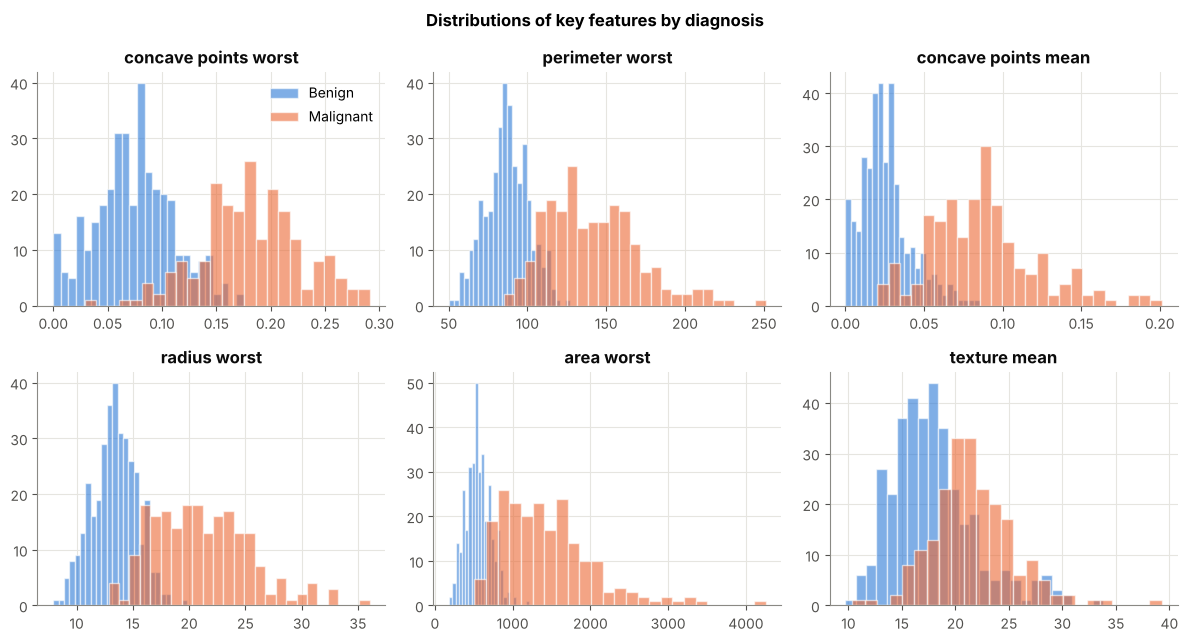

In [5]:
top6 = ["concave_points_worst", "perimeter_worst", "concave_points_mean", "radius_worst", "area_worst", "texture_mean"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, f in zip(axes.flat, top6):
    for cls in ["Benign", "Malignant"]:
        ax.hist(df.loc[df.diagnosis == cls, f], bins=25, alpha=0.6, color=CLASS_COLORS[cls], label=cls, edgecolor="white")
    ax.set_title(f.replace("_", " "))
axes[0, 0].legend()
fig.suptitle("Distributions of key features by diagnosis", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/01_feature_distributions.png", dpi=150, bbox_inches="tight")

Feature pairs with |r| > 0.9: 21


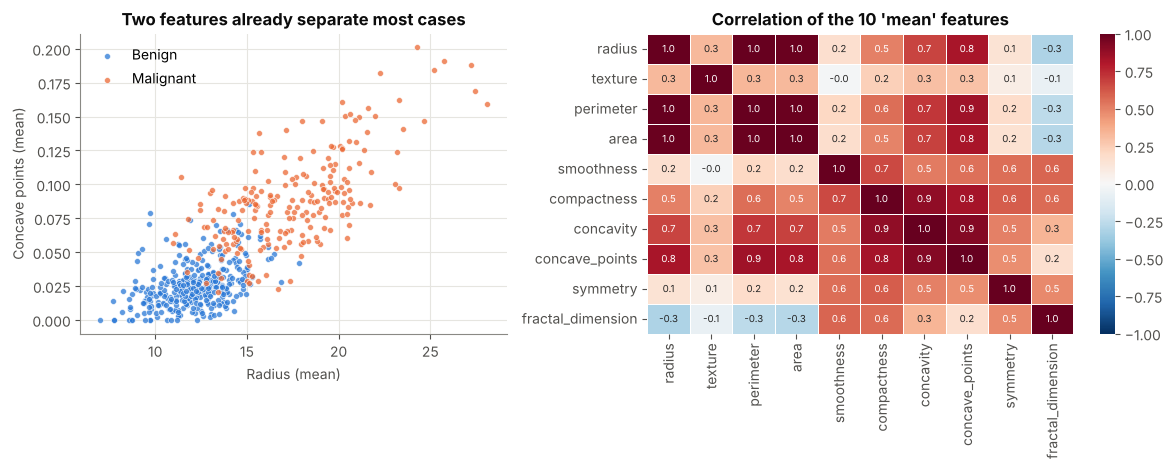

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
for cls in ["Benign", "Malignant"]:
    part = df[df.diagnosis == cls]
    axes[0].scatter(part.radius_mean, part.concave_points_mean, s=18, alpha=0.75, color=CLASS_COLORS[cls],
                    label=cls, edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Radius (mean)"); axes[0].set_ylabel("Concave points (mean)")
axes[0].set_title("Two features already separate most cases"); axes[0].legend()

mean_cols = [c for c in features if c.endswith("_mean")]
sns.heatmap(df[mean_cols].corr(), cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7},
            xticklabels=[c.replace("_mean", "") for c in mean_cols], yticklabels=[c.replace("_mean", "") for c in mean_cols],
            linewidths=0.5, linecolor="white", ax=axes[1])
axes[1].set_title("Correlation of the 10 'mean' features")
plt.tight_layout()
plt.savefig("figures/02_scatter_and_correlation.png", dpi=150, bbox_inches="tight")
high = (df[features].corr().abs().where(np.triu(np.ones((30, 30)), k=1).astype(bool)) > 0.9).sum().sum()
print("Feature pairs with |r| > 0.9:", int(high))

**EDA findings**
- 26 of 30 features differ significantly between classes (after Bonferroni correction); size and shape-irregularity features (perimeter, radius, area, concave points) differ most.
- Radius, perimeter and area are almost the same information (r ≈ 1.0) → strong multicollinearity, so regularised or tree-based models are preferred.
- Many features are right-skewed and on very different scales (area in hundreds, smoothness ≈ 0.1) → scaling is required for distance- and margin-based models.
- Classes are imbalanced (37% malignant) → use stratified splits and judge models by recall/precision, not accuracy alone.

## 4. Feature engineering

In [7]:
eng = df.copy()
# 1. Spread between the worst and the average nucleus (irregular samples have a few very abnormal cells)
eng["radius_worst_to_mean"] = eng.radius_worst / eng.radius_mean
eng["concavity_worst_to_mean"] = eng.concave_points_worst / (eng.concave_points_mean + 1e-6)
# 2. Shape compactness independent of size: perimeter^2 / area (a circle = 4*pi = 12.57)
eng["shape_irregularity"] = eng.perimeter_mean ** 2 / eng.area_mean
# 3. Log-transform heavily skewed area / SE features
for f in ["area_mean", "area_worst", "area_se", "perimeter_se", "radius_se"]:
    eng[f"log_{f}"] = np.log1p(eng[f])
new_feats = ["radius_worst_to_mean", "concavity_worst_to_mean", "shape_irregularity"] + [f"log_{f}" for f in ["area_mean", "area_worst", "area_se", "perimeter_se", "radius_se"]]
print("Skew before/after log:", {f: (round(df[f].skew(), 2), round(eng['log_' + f].skew(), 2)) for f in ["area_se", "area_worst"]})
display(eng.groupby("diagnosis")[new_feats[:3]].mean().round(3))

ALL = features + new_feats
X, y = eng[ALL], eng["malignant"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print(f"Train {X_train.shape}, test {X_test.shape}; malignant share train {y_train.mean():.1%}, test {y_test.mean():.1%}")

Skew before/after log: {'area_se': (np.float64(5.45), np.float64(0.85)), 'area_worst': (np.float64(1.86), np.float64(0.46))}


,radius_worst_to_mean,concavity_worst_to_mean,shape_irregularity
diagnosis,,,
Benign,1.102,3.139,13.458
Malignant,1.210,2.236,14.057


Train (455, 38), test (114, 38); malignant share train 37.4%, test 36.8%


## 5. Model building and comparison (5-fold stratified cross-validation on the training set)

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
scale = lambda m: Pipeline([("scale", StandardScaler()), ("model", m)])
models = {
    "Baseline (always benign)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": scale(LogisticRegression(max_iter=5000, random_state=RS)),
    "K-Nearest Neighbours": scale(KNeighborsClassifier(n_neighbors=7)),
    "Support Vector Machine": scale(SVC(kernel="rbf", probability=True, random_state=RS)),
    "Random Forest": RandomForestClassifier(n_estimators=400, random_state=RS),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RS),
}
scoring = {"accuracy": "accuracy", "recall": "recall", "precision": "precision", "f1": "f1", "roc_auc": "roc_auc"}
rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    rows.append([name] + [r[f"test_{k}"].mean() for k in scoring] + [r["test_recall"].std()])
cv_table = pd.DataFrame(rows, columns=["Model", "Accuracy", "Recall", "Precision", "F1", "ROC-AUC", "Recall std"]).set_index("Model")
display(cv_table.sort_values("ROC-AUC", ascending=False).round(3))
cv_table.to_csv("output/cv_model_comparison.csv")

,Accuracy,Recall,Precision,F1,ROC-AUC,Recall std
Model,,,,,,
Logistic Regression,0.969,0.953,0.965,0.959,0.996,0.024
Support Vector Machine,0.971,0.941,0.982,0.961,0.996,0.042
Gradient Boosting,0.971,0.947,0.976,0.961,0.991,0.022
K-Nearest Neighbours,0.965,0.918,0.988,0.951,0.989,0.034
Random Forest,0.965,0.941,0.964,0.952,0.988,0.037
Baseline (always benign),0.626,0.000,0.000,0.000,0.500,0.000


In [9]:
# Does feature engineering help? Same model, original 30 features vs 30 + 8 engineered
lr = scale(LogisticRegression(max_iter=5000, random_state=RS))
for label, cols in [("Original 30 features", features), ("With engineered features", ALL)]:
    r = cross_validate(lr, X_train[cols], y_train, cv=cv, scoring=["roc_auc", "recall", "f1"])
    print(f"{label:26} ROC-AUC {r['test_roc_auc'].mean():.4f} | recall {r['test_recall'].mean():.3f} | F1 {r['test_f1'].mean():.3f}")

Original 30 features       ROC-AUC 0.9958 | recall 0.953 | F1 0.964
With engineered features   ROC-AUC 0.9961 | recall 0.953 | F1 0.959


## 6. Hyperparameter tuning of the two best models

In [10]:
grids = {
    "Logistic Regression": (scale(LogisticRegression(max_iter=5000, random_state=RS)),
                            {"model__C": [0.01, 0.1, 0.3, 1, 3, 10], "model__class_weight": [None, "balanced"]}),
    "Support Vector Machine": (scale(SVC(kernel="rbf", probability=True, random_state=RS)),
                               {"model__C": [0.3, 1, 3, 10, 30], "model__gamma": ["scale", 0.003, 0.01, 0.03], "model__class_weight": [None, "balanced"]}),
}
tuned = {}
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    print(f"{name:24} best CV ROC-AUC {gs.best_score_:.4f} with {gs.best_params_}")

Logistic Regression      best CV ROC-AUC 0.9961 with {'model__C': 1, 'model__class_weight': None}
Support Vector Machine   best CV ROC-AUC 0.9962 with {'model__C': 10, 'model__class_weight': 'balanced', 'model__gamma': 0.003}


## 7. Choosing a safe decision threshold
The default threshold (0.5) is not chosen for safety. Using **out-of-fold** probabilities on the training set only, we find the highest threshold that still reaches recall ≥ 0.97.

In [11]:
best_name = "Logistic Regression"
best = tuned[best_name]
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thr_rows = []
for t in np.arange(0.05, 0.96, 0.05):
    p = (oof >= t).astype(int)
    thr_rows.append([round(t, 2), recall_score(y_train, p), precision_score(y_train, p), f1_score(y_train, p), (p != y_train).sum()])
thr = pd.DataFrame(thr_rows, columns=["threshold", "recall", "precision", "f1", "errors"])
display(thr.round(3))
ok = thr[thr.recall >= 0.97]
THRESHOLD = float(ok.threshold.max())
print("Chosen threshold:", THRESHOLD)

,threshold,recall,precision,f1,errors
0,0.05,0.994,0.801,0.887,43
1,0.10,0.988,0.866,0.923,28
2,0.15,0.988,0.898,0.941,21
3,0.20,0.988,0.913,0.949,18
4,0.25,0.982,0.938,0.960,14
5,0.30,0.965,0.959,0.962,13
6,0.35,0.959,0.959,0.959,14
7,0.40,0.959,0.964,0.962,13
8,0.45,0.953,0.964,0.959,14
9,0.50,0.953,0.964,0.959,14


Chosen threshold: 0.25


## 8. Final evaluation on the untouched test set

In [12]:
def evaluate(model, name, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Model": name, "Threshold": threshold, "Accuracy": accuracy_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, proba),
            "Missed cancers (FN)": fn, "False alarms (FP)": fp}

for m in tuned.values():
    m.fit(X_train, y_train)
rf = models["Random Forest"].fit(X_train, y_train)
final = pd.DataFrame([
    evaluate(tuned["Logistic Regression"], "Logistic Regression (tuned)", 0.5),
    evaluate(tuned["Logistic Regression"], "Logistic Regression (tuned)", THRESHOLD),
    evaluate(tuned["Support Vector Machine"], "SVM (tuned)", 0.5),
    evaluate(rf, "Random Forest", 0.5),
])
display(final.round(3))
final.to_csv("output/test_set_results.csv", index=False)
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= THRESHOLD).astype(int)
print(classification_report(y_test, pred, target_names=["Benign", "Malignant"], digits=3))

,Model,Threshold,Accuracy,Recall,Precision,F1,ROC-AUC,Missed cancers (FN),False alarms (FP)
0,Logistic Regression (tuned),0.50,0.974,0.952,0.976,0.964,0.997,2,1
1,Logistic Regression (tuned),0.25,0.982,0.976,0.976,0.976,0.997,1,1
2,SVM (tuned),0.50,0.982,0.952,1.000,0.976,0.998,2,0
3,Random Forest,0.50,0.965,0.905,1.000,0.950,0.995,4,0


              precision    recall  f1-score   support

      Benign      0.986     0.986     0.986        72
   Malignant      0.976     0.976     0.976        42

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114



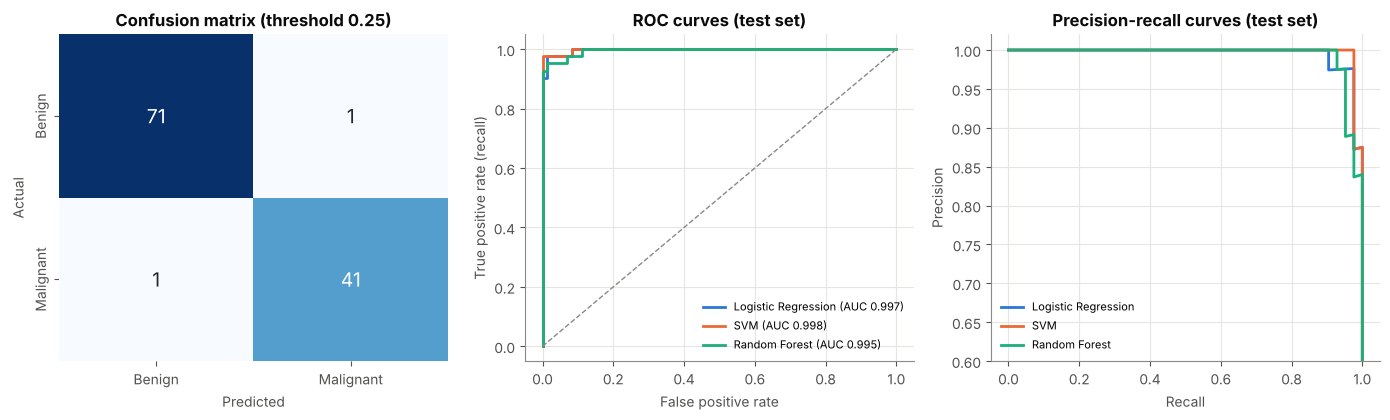

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 14},
            xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"], ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title(f"Confusion matrix (threshold {THRESHOLD})")

for (name, m), c in zip([("Logistic Regression", best), ("SVM", tuned["Support Vector Machine"]), ("Random Forest", rf)], [BLUE, ORANGE, AQUA]):
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, color=c, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[2].plot(rc, pr, color=c, label=name)
axes[1].plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1)
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curves (test set)"); axes[1].legend(loc="lower right", fontsize=8)
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-recall curves (test set)"); axes[2].legend(loc="lower left", fontsize=8)
axes[2].set_ylim(0.6, 1.02)
plt.tight_layout()
plt.savefig("figures/03_confusion_roc_pr.png", dpi=150, bbox_inches="tight")

## 9. Explaining the model

Top permutation importances (drop in ROC-AUC):
symmetry_worst          0.0071
concavity_worst         0.0053
texture_worst           0.0052
concave_points_mean     0.0021
concave_points_worst    0.0021
concavity_mean          0.0020


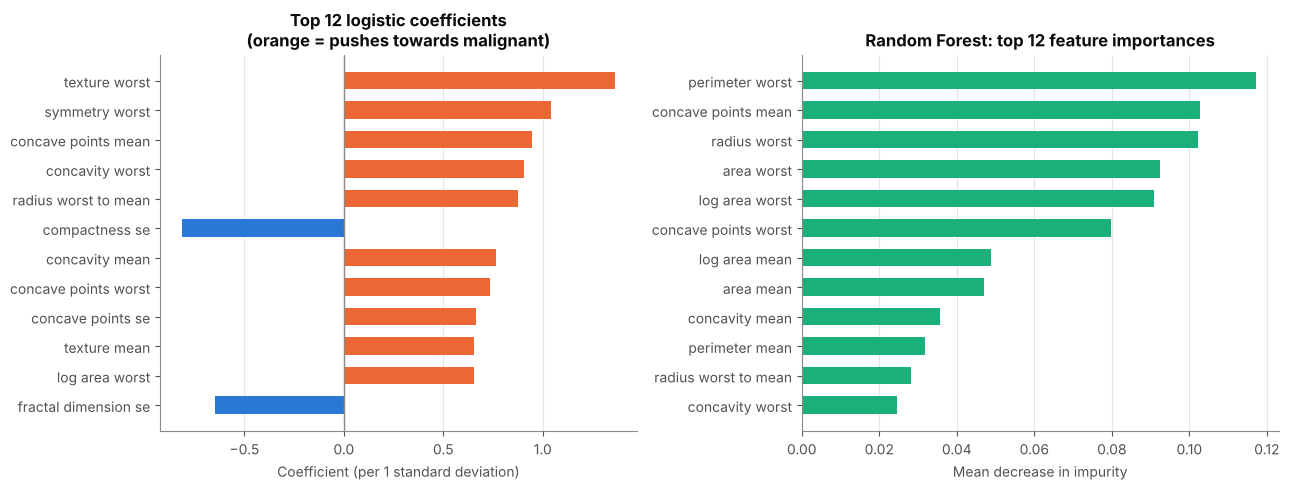

In [14]:
coef = pd.Series(best.named_steps["model"].coef_[0], index=ALL)
perm = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RS)
imp = pd.Series(perm.importances_mean, index=ALL).sort_values(ascending=False)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh([c.replace("_", " ") for c in top_coef.index], top_coef.values,
             color=[ORANGE if v > 0 else BLUE for v in top_coef.values], height=0.6)
axes[0].axvline(0, color=GREY, linewidth=1)
axes[0].set_title("Top 12 logistic coefficients\n(orange = pushes towards malignant)")
axes[0].set_xlabel("Coefficient (per 1 standard deviation)")
rf_imp = pd.Series(rf.feature_importances_, index=ALL).sort_values().tail(12)
axes[1].barh([c.replace("_", " ") for c in rf_imp.index], rf_imp.values, color=AQUA, height=0.6)
axes[1].set_title("Random Forest: top 12 feature importances")
axes[1].set_xlabel("Mean decrease in impurity")
for a in axes: a.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("figures/04_feature_importance.png", dpi=150, bbox_inches="tight")
print("Top permutation importances (drop in ROC-AUC):")
print(imp.head(6).round(4).to_string())

## 10. Error analysis

In [15]:
res = X_test.copy()
res["actual"] = y_test.map({1: "Malignant", 0: "Benign"})
res["prob_malignant"] = proba
res["predicted"] = np.where(pred == 1, "Malignant", "Benign")
errors = res[res.actual != res.predicted]
key = ["radius_mean", "concave_points_worst", "texture_mean", "area_worst"]
display(errors[["actual", "predicted", "prob_malignant"] + key].round(3))
class_means = eng.groupby("diagnosis")[key].mean().round(3)
display(class_means)
borderline = res[(res.prob_malignant > 0.2) & (res.prob_malignant < 0.8)]
print(f"Cases with uncertain probability (0.2-0.8): {len(borderline)} of {len(res)}; errors among them: {(borderline.actual != borderline.predicted).sum()}")

,actual,predicted,prob_malignant,radius_mean,concave_points_worst,texture_mean,area_worst
455,Benign,Malignant,0.635,13.38,0.078,30.72,705.6
73,Malignant,Benign,0.098,13.80,0.138,15.79,812.4


,radius_mean,concave_points_worst,texture_mean,area_worst
diagnosis,,,,
Benign,12.147,0.074,17.915,558.899
Malignant,17.463,0.182,21.605,1422.286


Cases with uncertain probability (0.2-0.8): 7 of 114; errors among them: 1


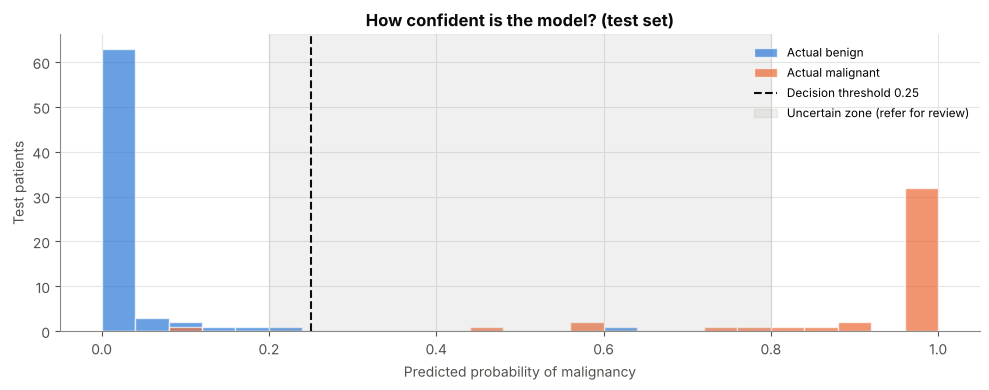

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
for cls, c in CLASS_COLORS.items():
    ax.hist(res.loc[res.actual == cls, "prob_malignant"], bins=np.linspace(0, 1, 26), alpha=0.7, color=c,
            label=f"Actual {cls.lower()}", edgecolor="white")
ax.axvline(THRESHOLD, color="#0b0b0b", linestyle="--", linewidth=1.5, label=f"Decision threshold {THRESHOLD}")
ax.axvspan(0.2, 0.8, color=GREY, alpha=0.12, label="Uncertain zone (refer for review)")
ax.set_xlabel("Predicted probability of malignancy"); ax.set_ylabel("Test patients")
ax.set_title("How confident is the model? (test set)")
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.savefig("figures/05_probability_distribution.png", dpi=150, bbox_inches="tight")

Gap at full size: train 0.9983 vs CV 0.9961


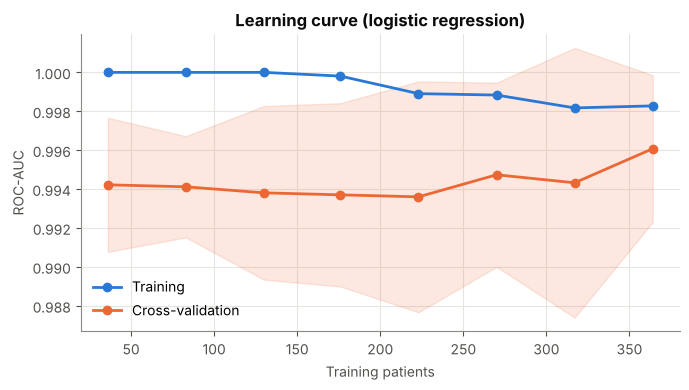

In [17]:
from sklearn.model_selection import learning_curve
sizes, tr, va = learning_curve(best, X_train, y_train, cv=cv, scoring="roc_auc",
                               train_sizes=np.linspace(0.1, 1.0, 8), random_state=RS)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, tr.mean(axis=1), marker="o", color=BLUE, label="Training")
ax.plot(sizes, va.mean(axis=1), marker="o", color=ORANGE, label="Cross-validation")
ax.fill_between(sizes, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color=ORANGE, alpha=0.15)
ax.set_xlabel("Training patients"); ax.set_ylabel("ROC-AUC"); ax.set_title("Learning curve (logistic regression)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/06_learning_curve.png", dpi=150, bbox_inches="tight")
print(f"Gap at full size: train {tr.mean(axis=1)[-1]:.4f} vs CV {va.mean(axis=1)[-1]:.4f}")

## 11. Conclusions
See the report and presentation for the full discussion of results, limitations, recommendations and future scope.